# Simpler guiding wavefunctions: Jastrow and RBM

**Question:** is a cheaper, geometry-independent positive guide more useful
than the current transformer-based pipeline on the difficult low-field cases?

We compare an all-pairs Jastrow wavefunction and real RBMs trained from scratch.
These are **selected $L=2$ diagnostics**, not finite-size scaling. Training uses
full-basis energy expectations to isolate ansatz/optimization behavior from
training-chain mixing. Exact eigenvectors are loaded **after fitting**, only for
evaluation. Larger-system sampled training remains unqualified.

This does not isolate ALiBi: the optimizer, per-disorder fitting, initialization,
and compute budget differ from the transformer pipeline. It does test whether
much simpler guides can avoid its observed metastable-sector failure.


## 1. Positive wavefunctions and cheap flip ratios

The two ansätze are
$$\log\psi_J(s)=\sum_i a_i s_i+\sum_{i<j}u_{ij}s_is_j,$$
$$\log\psi_{\rm RBM}(s)=\sum_i a_i s_i+
\sum_{\mu=1}^{\alpha N}\log[2\cosh(b_\mu+\sum_iW_{i\mu}s_i)].$$

Both have analytic single-spin ratios. For Jastrow,
$$\log\frac{\psi(s^{(i)})}{\psi(s)}=-2s_i(a_i+\sum_{j\ne i}u_{ij}s_j).$$
For RBM, cache $\theta_\mu=b_\mu+\sum_iW_{i\mu}s_i$ and replace it by
$\theta_\mu-2W_{i\mu}s_i$ for a flip. Neither ansatz needs token positions.

The direct RBM sampling adapter uses **two hidden copies**, since the target is
$\psi^2$, not $\psi$. Its finite Gibbs chains are not automatically independent
or equilibrated. The L2 GFMC experiment below instead uses enumerated guide
probabilities for initialization and lookup; this is explicitly a small-system
accelerator.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt

root = Path.cwd().resolve()
if not (root / 'code/transformer_qmc').exists():
    root = root.parent
sys.path.insert(0, str(root / 'code'))
from transformer_qmc.correlation_lengths import sha
from transformer_qmc.collective_campaign import label
from transformer_qmc.production_protocol import identity, geometry
from transformer_qmc.independent_replica_projector import spectrum_from_moments

folder = root / 'data/kagome/ltfim_simple_guides_v1'
screen = json.loads((folder / 'screen/review.json').read_text())['rows']
manifest = json.loads((folder / 'screen/manifest.json').read_text())
for row in screen:
    name = f"{label(row['gamma'],row['sample_id'])}_{row['kind']}_seed{row['seed']}"
    assert sha(folder / 'screen' / (name+'.npz')) == row['npz_sha256']
    assert row['source_sha256'] == manifest['source_sha256']
print('Validated fits:', len(screen))
print('Training settings:', manifest['settings'])
contexts = [(.25,50025),(.25,50059),(.5,50043),(.75,50004)]
kinds = ['jastrow','rbm_1','rbm_2']
selected = {(g,s,k): min([r for r in screen if
    (r['gamma'],r['sample_id'],r['kind']) == (g,s,k)], key=lambda r:r['energy'])
    for g,s in contexts for k in kinds}
print('Selection uses variational energy only; all seeds are retained.')


Validated fits: 36
Training settings: {'inputs': 'data/kagome/ltfim_correlation_expanded_v1', 'output': 'data/kagome/ltfim_simple_guides_v1/screen', 'device': 'cpu', 'seeds': 3, 'adam_steps': 800, 'lbfgs_steps': 200, 'kinds': ['jastrow', 'rbm_1', 'rbm_2']}
Selection uses variational energy only; all seeds are retained.


## 2. Every initialization, including metastable failures

Each fit uses 800 Adam steps followed by at most 200 L-BFGS iterations, with
three independent initializations per ansatz/context. The variational objective
is $\langle\psi|H|\psi\rangle/\langle\psi|\psi\rangle$ for the original LTFIM.
No fidelity, correlation, or exact-state label enters the objective or selection.

The plots distinguish energy, ground-state fidelity, and spectral error. A
low-variance excited-sector fit remains a failure, even when its energy looks
reasonable. Selecting the minimum-energy seed helps but does not guarantee
finding the ground sector in a larger system.


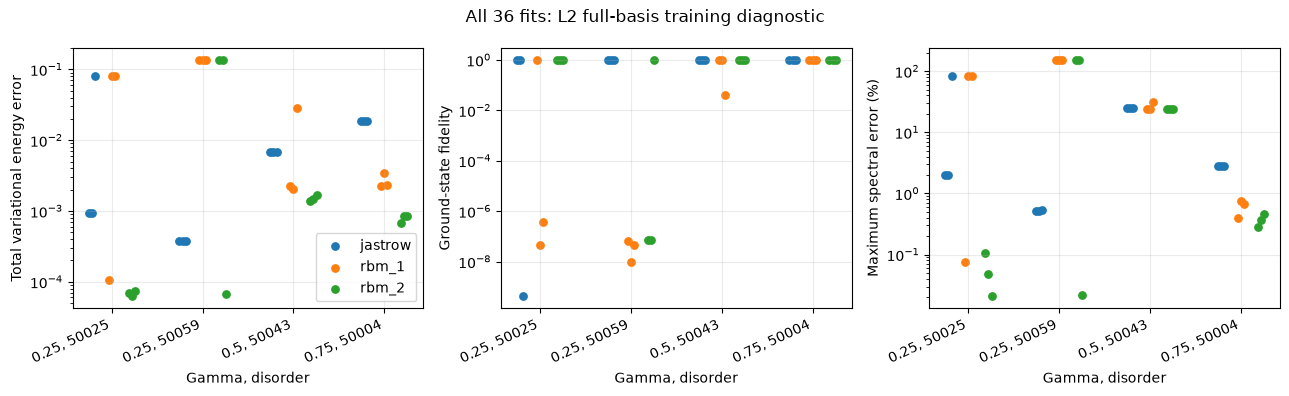

Lowest-energy seeds:
0.25 50025 jastrow  seed=0 E error=0.000923935 fidelity=0.998624468 spectral error=1.9756%
0.25 50025 rbm_1    seed=0 E error=0.000105148 fidelity=0.999974644 spectral error=0.0755%
0.25 50025 rbm_2    seed=1 E error=6.2046e-05 fidelity=0.999980396 spectral error=0.0480%
0.25 50059 jastrow  seed=1 E error=0.000382576 fidelity=0.999615986 spectral error=0.5190%
0.25 50059 rbm_1    seed=2 E error=0.136377 fidelity=0.000000046 spectral error=152.9558%
0.25 50059 rbm_2    seed=2 E error=6.83137e-05 fidelity=0.999987703 spectral error=0.0216%
0.50 50043 jastrow  seed=1 E error=0.00673369 fidelity=0.961326665 spectral error=25.0951%
0.50 50043 rbm_1    seed=1 E error=0.00206921 fidelity=0.963214047 spectral error=24.0733%
0.50 50043 rbm_2    seed=0 E error=0.00140503 fidelity=0.965227743 spectral error=23.8063%
0.75 50004 jastrow  seed=1 E error=0.0189604 fidelity=0.995982650 spectral error=2.7937%
0.75 50004 rbm_1    seed=0 E error=0.00228248 fidelity=0.999595800 spectr

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13,4))
colors = dict(jastrow='C0',rbm_1='C1',rbm_2='C2')
for j,kind in enumerate(kinds):
    for c,(g,s) in enumerate(contexts):
        rows = [r for r in screen if (r['gamma'],r['sample_id'],r['kind'])==(g,s,kind)]
        x = c+(j-1)*.22+np.linspace(-.035,.035,len(rows))
        values = [[r['energy_error'] for r in rows],
                  [r['fidelity'] for r in rows],
                  [100*r['max_spectral_relative_error'] for r in rows]]
        for ax,y in zip(axes,values):
            ax.scatter(x,y,color=colors[kind],s=28,label=kind if c==0 else None)
for ax in axes:
    ax.set_xticks(range(4),[f'{g}, {s}' for g,s in contexts],rotation=25,ha='right')
    ax.set_xlabel('Gamma, disorder');ax.grid(alpha=.25)
axes[0].set_yscale('log');axes[0].set_ylabel('Total variational energy error')
axes[1].set_yscale('log');axes[1].set_ylabel('Ground-state fidelity')
axes[2].set_yscale('log');axes[2].set_ylabel('Maximum spectral error (%)')
axes[0].legend();fig.suptitle('All 36 fits: L2 full-basis training diagnostic')
fig.tight_layout()
figure_dir=root/'figures/simple_guides';figure_dir.mkdir(parents=True,exist_ok=True)
fig.savefig(figure_dir/'all_seeds.png',dpi=180,bbox_inches='tight')
fig.savefig(figure_dir/'all_seeds.pdf',bbox_inches='tight')
plt.show()
print('Lowest-energy seeds:')
for (g,s,k),r in selected.items():
    print(f"{g:.2f} {s} {k:8s} seed={r['seed']} E error={r['energy_error']:.6g} "
          f"fidelity={r['fidelity']:.9f} spectral error={100*r['max_spectral_relative_error']:.4f}%")


## 3. Projection can still matter

The following is an **offline exact propagation diagnostic**, not a Monte Carlo
result. It evaluates the symmetric pure state proportional to
$[e^{-\tau H}\psi_T]^2$. This differs from the GFMC forward-walking schedule,
whose left projection grows over measurement cycles and whose right projection
is fixed. We do not treat these exact curves as that estimator's finite-time
target.


In [3]:
for (g,s,k),r in selected.items():
    print(f'{g:.2f} {s} {k:8s}:', ', '.join(
        f"tau={x['tau']:g}: {100*x['max_spectral_relative_error']:.4f}%"
        for x in r['projection']))


0.25 50025 jastrow : tau=8: 0.1408%, tau=32: 0.0000%, tau=64: 0.0000%
0.25 50025 rbm_1   : tau=8: 0.0049%, tau=32: 0.0000%, tau=64: 0.0000%
0.25 50025 rbm_2   : tau=8: 0.0030%, tau=32: 0.0000%, tau=64: 0.0000%
0.25 50059 jastrow : tau=8: 0.0041%, tau=32: 0.0000%, tau=64: 0.0000%
0.25 50059 rbm_1   : tau=8: 152.9669%, tau=32: 153.0412%, tau=64: 11858.9953%
0.25 50059 rbm_2   : tau=8: 0.0006%, tau=32: 0.0000%, tau=64: 0.0000%
0.50 50043 jastrow : tau=8: 23.1500%, tau=32: 17.9100%, tau=64: 9.4431%
0.50 50043 rbm_1   : tau=8: 23.0928%, tau=32: 17.8035%, tau=64: 9.3594%
0.50 50043 rbm_2   : tau=8: 22.9651%, tau=32: 17.5395%, tau=64: 9.1549%
0.75 50004 jastrow : tau=8: 0.2897%, tau=32: 0.0002%, tau=64: 0.0000%
0.75 50004 rbm_1   : tau=8: 0.0301%, tau=32: 0.0000%, tau=64: 0.0000%
0.75 50004 rbm_2   : tau=8: 0.0232%, tau=32: 0.0000%, tau=64: 0.0000%


## 4. Matched GFMC with frozen selected guides

For each ansatz/context, freeze the minimum-energy fit and compare continuous
time and Hamiltonian-aware triangle GFMC at step 0.1. Each run uses four
independently resampled populations, 1024 walkers per population, equilibration
32, forward time 32, and 16 measurement cycles. There are four whole-run repeats.

Connected spectra use products of moments from disjoint populations. We verify
each raw archive hash and reconstruct the spectrum from saved moments. Whole
runs, not walkers, are the uncertainty units. The plots show all selected
contexts, including failed guides. Four repeats and one population/time setting
do not establish controlled ground-state convergence.


Validated GFMC runs: 96


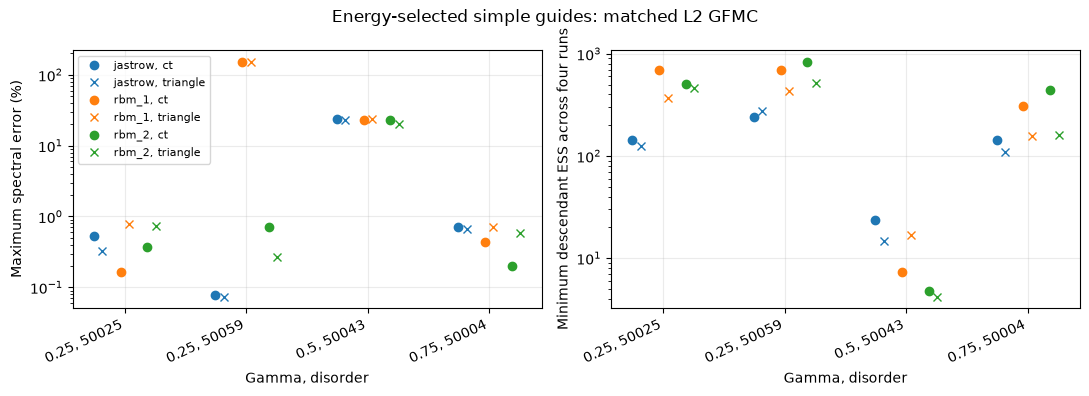

0.25 50025 jastrow  ct      : spectral error=0.522% alarms=0/4
0.25 50025 jastrow  triangle: spectral error=0.322% alarms=0/4
0.25 50059 jastrow  ct      : spectral error=0.078% alarms=0/4
0.25 50059 jastrow  triangle: spectral error=0.074% alarms=0/4
0.50 50043 jastrow  ct      : spectral error=23.390% alarms=0/4
0.50 50043 jastrow  triangle: spectral error=22.733% alarms=0/4
0.75 50004 jastrow  ct      : spectral error=0.717% alarms=0/4
0.75 50004 jastrow  triangle: spectral error=0.659% alarms=0/4
0.25 50025 rbm_1    ct      : spectral error=0.162% alarms=0/4
0.25 50025 rbm_1    triangle: spectral error=0.791% alarms=0/4
0.25 50059 rbm_1    ct      : spectral error=153.028% alarms=0/4
0.25 50059 rbm_1    triangle: spectral error=152.574% alarms=0/4
0.50 50043 rbm_1    ct      : spectral error=22.860% alarms=1/4
0.50 50043 rbm_1    triangle: spectral error=23.443% alarms=0/4
0.75 50004 rbm_1    ct      : spectral error=0.437% alarms=0/4
0.75 50004 rbm_1    triangle: spectral error=0.

In [4]:
projection = json.loads((folder/'projector/review.json').read_text())['rows']
project_manifest=json.loads((folder/'projector/manifest.json').read_text())
validated=0
for path in sorted((folder/'projector').glob('*/runs/*.json')):
    r=json.loads(path.read_text())
    assert sha(path.with_suffix('.npz'))==r['npz_sha256']
    assert r['provenance']['source_sha256']==project_manifest['source_sha256']
    with np.load(path.with_suffix('.npz')) as a:
        measured=spectrum_from_moments(a['magnetization_cycles'].mean(1),a['pair_cycles'].mean(1),geometry(2))
    np.testing.assert_allclose(measured,r['spectrum'],atol=1e-12)
    validated+=1
print('Validated GFMC runs:',validated)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for j,kind in enumerate(kinds):
    for method,marker,offset in [('ct','o',-.035),('triangle','x',.035)]:
        rows=[next(r for r in projection if (r['gamma'],r['sample_id'],r['kind'],r['method'])==(g,s,kind,method)) for g,s in contexts]
        x=np.arange(4)+(j-1)*.22+offset
        axes[0].plot(x,[100*r['max_relative_error'] for r in rows],marker,ls='none',color=colors[kind],label=f'{kind}, {method}')
        axes[1].plot(x,[r['minimum_descendant_ess'] for r in rows],marker,ls='none',color=colors[kind])
for ax in axes:
    ax.set_xticks(range(4),[f'{g}, {s}' for g,s in contexts],rotation=25,ha='right')
    ax.set_xlabel('Gamma, disorder');ax.grid(alpha=.25)
axes[0].set_yscale('log');axes[0].set_ylabel('Maximum spectral error (%)');axes[0].legend(fontsize=8)
axes[1].set_yscale('log');axes[1].set_ylabel('Minimum descendant ESS across four runs')
fig.suptitle('Energy-selected simple guides: matched L2 GFMC')
fig.tight_layout();fig.savefig(figure_dir/'gfmc_comparison.png',dpi=180,bbox_inches='tight')
fig.savefig(figure_dir/'gfmc_comparison.pdf',bbox_inches='tight');plt.show()
for r in projection:
    print(f"{r['gamma']:.2f} {r['sample_id']} {r['kind']:8s} {r['method']:8s}: "
          f"spectral error={100*r['max_relative_error']:.3f}% alarms={r['alarms']}/{r['repeats']}")


## Interpretation and limits

The comparison tests **guide representation plus optimization**, and does not
prove that ALiBi caused the transformer failure. RBM and Jastrow also have
metastable optimization failures. The retained seed-level results make this
visible instead of reporting only successful fits.

The original finite-size target remains $\xi_R/L$ versus $\Gamma$ and versus
$L$ at $h=0.15$, with disorder spectra averaged before taking the length ratio.
Four selected L2 contexts cannot supply those curves. Before extrapolating,
simple guides need sampled training, mixing checks, direct-guide timing, and
population/projection/step-size convergence at larger L.

Sources: [guide definitions](../code/transformer_qmc/simple_guides.py),
[energy-only fitting](../code/transformer_qmc/simple_guide_benchmark.py),
[GFMC comparison](../code/transformer_qmc/simple_guide_projector.py), and
[method notes](../code/transformer_qmc/SIMPLE_GUIDES.md).


## 5. Sampled training on AutoDL: frozen snapshot

This follow-up trains on samples only. Eight parallel-tempering levels target
$\psi^{2\beta}$, with 256 chains per level, local spin flips, global inversion,
uniform refreshes at $\beta=0$, and exact replica exchanges. Cached fields make
each proposal inexpensive. Adaptive training samples are not convergence data.

Compare direct training at the target field with continuation from $\Gamma=1.5$
through 0.75 to the target. Each stage uses 400 Adam updates. **Continuation uses
more total updates:** this experiment cannot distinguish schedule effects from
additional compute. All seeds are retained, and no exact-state label enters
training. The original Hamiltonian is restored at the target stage.

After parameters are frozen, new random/up/down starts are measured separately.
Each uses 200 warmup and 200 measurement sweeps, recording every fourth sweep.
For L2 only, post-training enumeration measures ground fidelity and the total
variation distance between sampled histograms and the fitted guide's exact
probability. Finite histograms and autocorrelation contribute to that distance.
Temperature round trips alone do not establish valley equilibration.

The snapshot is partial and tasks run in a fixed order; it is not an unbiased
summary of the whole planned campaign. L4 feasibility tasks may still be pending.


Frozen sampled-training fits: 31
Campaign state at snapshot: {'state': 'training', 'task': {'L': 2, 'gamma': 0.75, 'sample_id': 50004, 'kind': 'rbm_2', 'seed': 1, 'mode': 'anneal'}, 'stage': 0, 'gamma': 1.5, 'step': 275, 'energy': -21.024878913121412, 'variance': 0.11635624105656968, 'gradient_norm': 0.03923958857357651}
Gamma=0.25 s=50025 jastrow  seed=0 direct: fidelity=0.996576, spectral error=5.03%, guide histogram TV=0.0091..0.0124
Gamma=0.25 s=50025 jastrow  seed=0 anneal: fidelity=0.997645, spectral error=4.23%, guide histogram TV=0.0073..0.0115
Gamma=0.25 s=50025 jastrow  seed=1 direct: fidelity=0.010409, spectral error=55.99%, guide histogram TV=0.0080..0.0121
Gamma=0.25 s=50025 jastrow  seed=1 anneal: fidelity=0.998082, spectral error=0.36%, guide histogram TV=0.0089..0.0118
Gamma=0.25 s=50025 rbm_2    seed=0 direct: fidelity=0.007217, spectral error=48.05%, guide histogram TV=0.0073..0.0122
Gamma=0.25 s=50025 rbm_2    seed=0 anneal: fidelity=0.982872, spectral error=4.52%, g

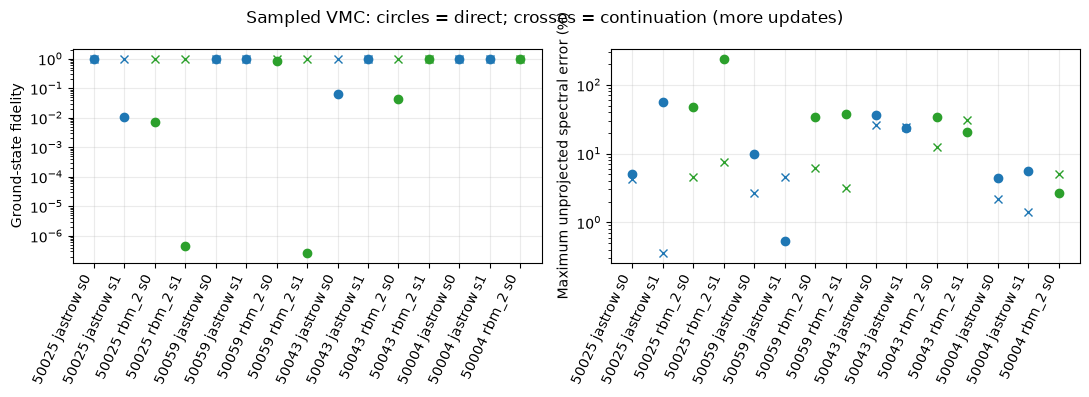

In [5]:
sampled=json.loads((folder/'sampled_snapshot.json').read_text())
print('Frozen sampled-training fits:',len(sampled['rows']))
print('Campaign state at snapshot:',sampled['campaign_status'])
for r in sampled['rows']:
    t=r['task'];e=r.get('exact_evaluation')
    if e is None:
        print(t,'larger-L feasibility only');continue
    tv=[d['tv_from_exact_guide_probability'] for d in r['diagnostics']]
    print(f"Gamma={t['gamma']} s={t['sample_id']} {t['kind']:8s} seed={t['seed']} {t['mode']:6s}: "
          f"fidelity={e['fidelity']:.6f}, spectral error={100*e['max_spectral_error']:.2f}%, "
          f"guide histogram TV={min(tv):.4f}..{max(tv):.4f}")

complete=[]
for r in sampled['rows']:
    t=r['task']
    if t['mode']!='direct' or 'exact_evaluation' not in r:continue
    matches=[a for a in sampled['rows'] if a['task']==dict(t,mode='anneal')]
    if matches:complete.append((r,matches[0]))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for i,(direct,anneal) in enumerate(complete):
    for r,marker in [(direct,'o'),(anneal,'x')]:
        e=r['exact_evaluation'];t=r['task']
        axes[0].plot(i,e['fidelity'],marker,color=colors[t['kind']])
        axes[1].plot(i,100*e['max_spectral_error'],marker,color=colors[t['kind']])
labels=[f"{a['task']['sample_id']} {a['task']['kind']} s{a['task']['seed']}" for a,b in complete]
for ax in axes:
    ax.set_xticks(range(len(labels)),labels,rotation=65,ha='right');ax.grid(alpha=.25)
axes[0].set_yscale('log');axes[0].set_ylabel('Ground-state fidelity')
axes[1].set_yscale('log');axes[1].set_ylabel('Maximum unprojected spectral error (%)')
fig.suptitle('Sampled VMC: circles = direct; crosses = continuation (more updates)')
fig.tight_layout();fig.savefig(figure_dir/'sampled_snapshot.png',dpi=180,bbox_inches='tight')
fig.savefig(figure_dir/'sampled_snapshot.pdf',bbox_inches='tight');plt.show()


The full-basis and sampled-training experiments answer different questions.
The former demonstrates that simple ansätze can represent useful low-field
guides. The latter tests whether sampling and optimization can find them. A
successful L2 guide is not yet a scalable protocol: matched-compute schedules,
more optimization seeds, L4 mixing, and GFMC sensitivity checks remain necessary.


## 6. Completed GFMC sensitivity audit

The 64 additional runs test 4096 walkers, doubled equilibration/forward times,
uniform initial states, and triangle step 0.05. Each audit group has two repeats.
Exact CT references use the actual forward-walking schedule, including growing
left projection over cycles and fixed right projection. Their discrepancy from
the ground state is finite-time bias; measured discrepancies from those
references contain population/sampling effects.

At $\Gamma=0.5$, neither longer projection nor larger population establishes
convergence. Uniform starts can improve apparent spectra while raising ancestry
alarms. Such runs remain unresolved. The table retains all groups and invalid
length fractions; bootstrap intervals from two runs are descriptive only.


In [6]:
audit=json.loads((folder/'audit/review.json').read_text())
print('Audit status:',json.loads((folder/'audit/status.json').read_text()))
print('kind Gamma disorder method audit error(%) alarms invalid-xi-fraction')
for r in audit['rows']:
    print(r['kind'],r['gamma'],r['sample_id'],r['method'],r['audit'],
          round(100*r['max_relative_error'],3),r['alarms'],r['invalid_length_fraction'])
print('Gamma=0.5 CT error decomposition:')
for r in audit['rows']:
    if r['gamma']==.5 and r['method']=='ct':
        print(r['kind'],r['audit'],
              'finite-time error (%)',np.round(100*np.array(r['finite_projection_relative_error']),2),
              'sampling relative to finite target (%)',np.round(100*np.array(r['relative_sampling_error']),2))


Audit status: {'state': 'completed', 'completed': 64, 'total': 64}
kind Gamma disorder method audit error(%) alarms invalid-xi-fraction
jastrow 0.25 50025 ct main 0.522 0 0.0
jastrow 0.25 50025 ct population 0.292 0 0.0
jastrow 0.25 50025 ct start 0.823 0 0.0
jastrow 0.25 50025 ct time 0.679 0 0.0
jastrow 0.25 50025 triangle step 0.621 0 0.0
jastrow 0.25 50025 triangle main 0.322 0 0.0
jastrow 0.25 50059 ct main 0.078 0 0.0
jastrow 0.25 50059 ct population 0.1 0 0.0
jastrow 0.25 50059 ct start 0.277 0 0.0
jastrow 0.25 50059 ct time 0.239 0 0.0
jastrow 0.25 50059 triangle step 1.172 0 0.0
jastrow 0.25 50059 triangle main 0.074 0 0.0
jastrow 0.5 50043 ct main 23.39 0 0.0
jastrow 0.5 50043 ct population 23.415 1 0.0
jastrow 0.5 50043 ct start 24.013 2 0.0
jastrow 0.5 50043 ct time 23.496 1 0.0
jastrow 0.5 50043 triangle step 22.009 0 0.0
jastrow 0.5 50043 triangle main 22.733 0 0.0
jastrow 0.75 50004 ct main 0.717 0 0.0
jastrow 0.75 50004 ct population 0.186 0 0.0
jastrow 0.75 50004 ct st